# 03. Regression
Does first-year retention predict six-year graduation across public research universities? OLS on the most recent year, one row per institution.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
peers = pd.read_csv(ROOT / "data/clean/ipeds_peers.csv")
year = peers["year"].max()
d = peers[peers["year"] == year].copy()
d["log_enrollment"] = np.log(d["enrollment"])
m1 = smf.ols("grad_rate_6yr ~ retention_rate", d).fit()
m2 = smf.ols("grad_rate_6yr ~ retention_rate + log_enrollment", d).fit()
print(year, len(d)); print(m1.summary()); print(m2.summary())

2023 106
                            OLS Regression Results                            
Dep. Variable:          grad_rate_6yr   R-squared:                       0.883
Model:                            OLS   Adj. R-squared:                  0.881
Method:                 Least Squares   F-statistic:                     781.8
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           3.49e-50
Time:                        14:40:17   Log-Likelihood:                -306.23
No. Observations:                 106   AIC:                             616.5
Df Residuals:                     104   BIC:                             621.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        -73.4421      5.22

## Fit checks
Heteroskedasticity-robust errors and leave-out checks show whether a few low-retention schools drive the slope.

In [2]:
robust = m1.get_robustcov_results("HC3")
print("HC3 slope CI:", robust.conf_int()[1].round(3))
influence = m1.get_influence().cooks_distance[0]
d["cooks"] = influence
print(d.nlargest(5, "cooks")[["institution", "retention_rate", "grad_rate_6yr", "cooks"]].to_string(index=False))
trim = smf.ols("grad_rate_6yr ~ retention_rate", d[d["cooks"] < 4 / len(d)]).fit()
print("slope without high-influence schools:", round(trim.params["retention_rate"], 3), "n", int(trim.nobs))
by_year = {int(y): round(smf.ols("grad_rate_6yr ~ retention_rate", g).fit().params["retention_rate"], 3)
           for y, g in peers.groupby("year")}
print("slope by year:", by_year)

HC3 slope CI: [1.545 1.816]
                       institution  retention_rate  grad_rate_6yr    cooks
     University of Hawaii at Manoa            75.0           62.6 0.096387
           Old Dominion University            76.0           44.4 0.082204
The University of Texas at El Paso            77.0           45.9 0.074076
University of Southern Mississippi            70.0           50.6 0.073592
         The University of Montana            76.0           45.4 0.066412
slope without high-influence schools: 1.727 n 98
slope by year: {2019: np.float64(1.793), 2020: np.float64(1.981), 2021: np.float64(1.661), 2022: np.float64(1.708), 2023: np.float64(1.681)}


## Where UIUC sits
Residual is actual minus predicted graduation rate.

In [3]:
d["predicted"] = m1.fittedvalues
d["residual"] = m1.resid
d["predicted_m2"] = m2.fittedvalues
d["residual_m2"] = m2.resid
uiuc = d[d["unitid"] == 145637].iloc[0]
d["resid_rank"] = d["residual"].rank(ascending=False).astype(int)
print(d[d["unitid"] == 145637][["institution", "retention_rate", "grad_rate_6yr", "enrollment", "predicted", "residual", "residual_m2", "resid_rank"]].T.to_string())
print("residual SD:", round(m1.resid.std(), 2))
print(d[d["big_ten"] == "Big Ten"].sort_values("grad_rate_6yr", ascending=False)[["institution", "retention_rate", "grad_rate_6yr", "residual"]].round(1).to_string(index=False))

                                                    453
institution     University of Illinois Urbana-Champaign
retention_rate                                     94.0
grad_rate_6yr                                      84.9
enrollment                                        56563
predicted                                     84.534861
residual                                       0.365139
residual_m2                                    0.304636
resid_rank                                           56
residual SD: 4.37
                              institution  retention_rate  grad_rate_6yr  residual
         University of Michigan-Ann Arbor            98.0           93.2       1.9
     University of California-Los Angeles            97.0           92.7       3.1
          University of Wisconsin-Madison            95.0           89.3       3.1
      University of Maryland-College Park            96.0           88.6       0.7
        Ohio State University-Main Campus            94.0      

                               model  slope  ci_low  ci_high p_value  r_squared   n
             Model 1: retention only  1.681   1.561    1.800 3.5e-50      0.883 106
Model 2: retention + log(enrollment)  1.675   1.536    1.814 9.7e-44      0.883 106


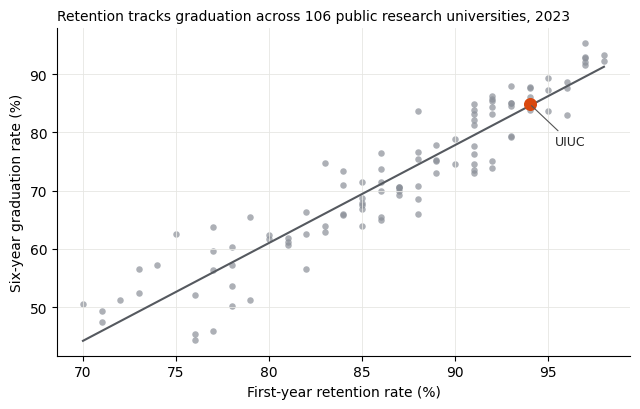

In [4]:
ROWS = []
for name, model in (("Model 1: retention only", m1), ("Model 2: retention + log(enrollment)", m2)):
    ci = model.conf_int().loc["retention_rate"]
    ROWS.append({"model": name, "slope": round(model.params["retention_rate"], 3), "ci_low": round(ci[0], 3), "ci_high": round(ci[1], 3),
                 "p_value": f"{model.pvalues['retention_rate']:.2g}", "r_squared": round(model.rsquared, 3), "n": int(model.nobs)})
table = pd.DataFrame(ROWS)
print(table.to_string(index=False))
lines = ["| Model | Slope on retention | 95% CI | p | R² | n |", "| --- | --- | --- | --- | --- | --- |"]
lines += [f"| {r.model} | {r.slope} | [{r.ci_low}, {r.ci_high}] | {r.p_value} | {r.r_squared} | {r.n} |" for r in table.itertuples()]
(ROOT / "notebooks/regression_table.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

(ROOT / "notebooks/regression_numbers.json").write_text(json.dumps({
    "year": int(year), "n": int(m1.nobs), "models": ROWS,
    "log_enrollment_coef": round(m2.params["log_enrollment"], 3), "log_enrollment_p": f"{m2.pvalues['log_enrollment']:.2g}",
    "uiuc": {k: round(float(uiuc[k]), 2) for k in ["retention_rate", "grad_rate_6yr", "predicted", "residual", "residual_m2"]},
    "uiuc_resid_rank": int(d.loc[d["unitid"] == 145637, "resid_rank"].iloc[0]), "residual_sd": round(float(m1.resid.std()), 2),
    "trim_slope": round(float(trim.params["retention_rate"]), 3), "slope_by_year": by_year}, indent=2))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
others = d[d["unitid"] != 145637]
ax.scatter(others["retention_rate"], others["grad_rate_6yr"], s=22, color="#8A8F98", alpha=.7, linewidth=0)
xs = np.linspace(d["retention_rate"].min(), d["retention_rate"].max(), 50)
ax.plot(xs, m1.params["Intercept"] + m1.params["retention_rate"] * xs, color="#55595F", lw=1.5)
ax.scatter([uiuc["retention_rate"]], [uiuc["grad_rate_6yr"]], s=70, color="#D9480F", zorder=3)
ax.annotate("UIUC", (uiuc["retention_rate"], uiuc["grad_rate_6yr"]), xytext=(18, -30), textcoords="offset points", ha="left", fontsize=9, color="#222",
            arrowprops={"arrowstyle": "-", "color": "#555", "lw": .8})
ax.set_xlabel("First-year retention rate (%)"); ax.set_ylabel("Six-year graduation rate (%)")
ax.set_title(f"Retention tracks graduation across {int(m1.nobs)} public research universities, {year}", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#E6E6E3", lw=.6)
fig.tight_layout(); fig.savefig(ROOT / "dashboard/preview/view3_peer_scatter.png", dpi=200); plt.show()

## Limits
- Institution-level and correlational. It does not show that raising retention at one school would raise its graduation rate, and it says nothing about individual students.
- Selective schools have high retention and high graduation for shared reasons such as student preparation and resources.
- With about 100 schools the estimate is rough.
- Rates come from different cohorts. In the 2023 files, retention follows students who entered in fall 2022 and graduation follows students who entered in 2017.
- Retention is capped near 100, so the relationship is compressed among top schools.